# 03 · Bayesian and kernel models

The task asks for Bayesian models: Bayesian ridge and Gaussian process regression. The old pipeline
had Bayesian ridge (BRR) but no GP.

- **BRR / ARD:** linear models with a Gaussian prior on the weights (ARD gives each weight its own prior).
- **GP, RBF kernel:** on standardised descriptor-type features (EState + functional groups).
- **GP, Tanimoto kernel:** the MinMax (generalised Tanimoto) similarity between count fingerprints,
  the usual choice for molecules with few samples. Variants: precomputed ECFP, our Morgan r=2 and
  atom-pair fingerprints, and ECFP **plus** an RBF kernel on the 8 basic descriptors (sum of kernels).
- For comparison, two non-Bayesian kernel methods on the same Tanimoto kernel: kernel ridge and SVR.

GP hyperparameters (kernel amplitudes, RBF length scale, noise) are fitted by maximising the marginal
likelihood on the training part of each fold. All models use the log target unless the name says `raw`.

In [1]:
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ARDRegression, BayesianRidge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

from cofreg import plots
from cofreg.cv import load_oof, repeated_folds, run_many
from cofreg.data import RESULTS_DIR, load_data, load_features
from cofreg.features import count_fingerprint
from cofreg.gp import TanimotoGP, TanimotoKernelModel
from cofreg.models import TargetTransformed

plots.style()
EXPERIMENT = "03_bayesian_models"
data = load_data()
y = data.capacity_max.to_numpy()
smiles = data.smiles.tolist()
repeats = repeated_folds(y)

X_brr = load_features("descriptor", "ecfp", "estate", "functional_groups")
X_rf = load_features("estate", "functional_groups")
ecfp = load_features("ecfp")
desc = load_features("descriptor")
morgan = count_fingerprint(smiles, "morgan", radius=2, size=2048)
atompair = count_fingerprint(smiles, "atompair", size=2048)
ecfp_desc = pd.concat([ecfp, desc], axis=1)
log = lambda model: TargetTransformed(model, "log")

In [2]:
configs = [
    ("brr_raw | desc+ecfp+estate+fg", TargetTransformed(make_pipeline(StandardScaler(), BayesianRidge()), "none"), X_brr, "descriptor+ecfp+estate+fg"),
    ("brr | desc+ecfp+estate+fg", log(make_pipeline(StandardScaler(), BayesianRidge())), X_brr, "descriptor+ecfp+estate+fg"),
    ("brr | estate+fg", log(make_pipeline(StandardScaler(), BayesianRidge())), X_rf, "estate+fg"),
    ("ard | estate+fg", log(make_pipeline(StandardScaler(), ARDRegression())), X_rf, "estate+fg"),
    ("gp_rbf | estate+fg", log(TanimotoGP(n_fp=0)), X_rf, "estate+fg"),
    ("gp_tanimoto_raw | ecfp", TanimotoGP(), ecfp, "ecfp"),
    ("gp_tanimoto | ecfp", log(TanimotoGP()), ecfp, "ecfp"),
    ("gp_tanimoto | morgan2", log(TanimotoGP()), morgan, "morgan2"),
    ("gp_tanimoto | atompair", log(TanimotoGP()), atompair, "atompair"),
    ("gp_tanimoto+rbf | ecfp+descriptor", log(TanimotoGP(n_fp=ecfp.shape[1])), ecfp_desc, "ecfp+descriptor"),
    ("krr_tanimoto | ecfp", log(TanimotoKernelModel(KernelRidge(alpha=0.3, kernel="precomputed"))), ecfp, "ecfp"),
    ("svr_tanimoto | ecfp", log(TanimotoKernelModel(SVR(kernel="precomputed", C=3, epsilon=0.1))), ecfp, "ecfp"),
]
summary = run_many(configs, y, repeats, EXPERIMENT)
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)
summary[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

brr_raw | desc+ecfp+estate+fg                 MAPE 3.655±0.080  PA 0.666±0.009  RMSE 177.8±2.6  MALE 0.786  (1.5s)
brr | desc+ecfp+estate+fg                     MAPE 2.201±0.091  PA 0.661±0.011  RMSE 197.2±2.1  MALE 0.812  (0.1s)
brr | estate+fg                               MAPE 2.536±0.065  PA 0.626±0.008  RMSE 206.5±1.2  MALE 0.860  (0.0s)


ard | estate+fg                               MAPE 2.707±0.051  PA 0.636±0.007  RMSE 204.3±2.0  MALE 0.859  (0.1s)


gp_rbf | estate+fg                            MAPE 1.535±0.017  PA 0.626±0.007  RMSE 200.2±1.4  MALE 0.759  (0.5s)


gp_tanimoto_raw | ecfp                        MAPE 3.431±0.066  PA 0.652±0.007  RMSE 180.0±1.7  MALE 0.793  (11.2s)


gp_tanimoto | ecfp                            MAPE 1.776±0.052  PA 0.658±0.007  RMSE 196.9±2.4  MALE 0.741  (9.8s)


...

gp_tanimoto | atompair                        MAPE 1.847±0.050  PA 0.641±0.012  RMSE 200.1±2.4  MALE 0.747  (64.1s)


gp_tanimoto+rbf | ecfp+descriptor             MAPE 1.577±0.053  PA 0.663±0.007  RMSE 194.2±1.1  MALE 0.704  (27.8s)


krr_tanimoto | ecfp                           MAPE 1.146±0.032  PA 0.616±0.008  RMSE 227.1±2.4  MALE 0.937  (0.2s)


svr_tanimoto | ecfp                           MAPE 1.853±0.152  PA 0.660±0.012  RMSE 193.8±3.8  MALE 0.712  (0.3s)


,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean
0,brr_raw | desc+ecfp+estate+fg,3.655,0.666,0.009,177.788,0.786,0.850,0.174
1,brr | desc+ecfp+estate+fg,2.201,0.661,0.011,197.163,0.812,0.667,-0.015
2,brr | estate+fg,2.536,0.626,0.008,206.520,0.860,0.703,-0.114
3,ard | estate+fg,2.707,0.636,0.007,204.289,0.859,0.700,-0.090
4,gp_rbf | estate+fg,1.535,0.626,0.007,200.155,0.759,0.776,-0.046
5,gp_tanimoto_raw | ecfp,3.431,0.652,0.007,179.963,0.793,0.914,0.154
6,gp_tanimoto | ecfp,1.776,0.658,0.007,196.857,0.741,0.656,-0.012
7,gp_tanimoto | morgan2,1.767,0.658,0.006,198.348,0.751,0.659,-0.027
8,gp_tanimoto | atompair,1.847,0.641,0.012,200.098,0.747,0.657,-0.046
9,gp_tanimoto+rbf | ecfp+descriptor,1.577,0.663,0.007,194.219,0.704,0.667,0.015


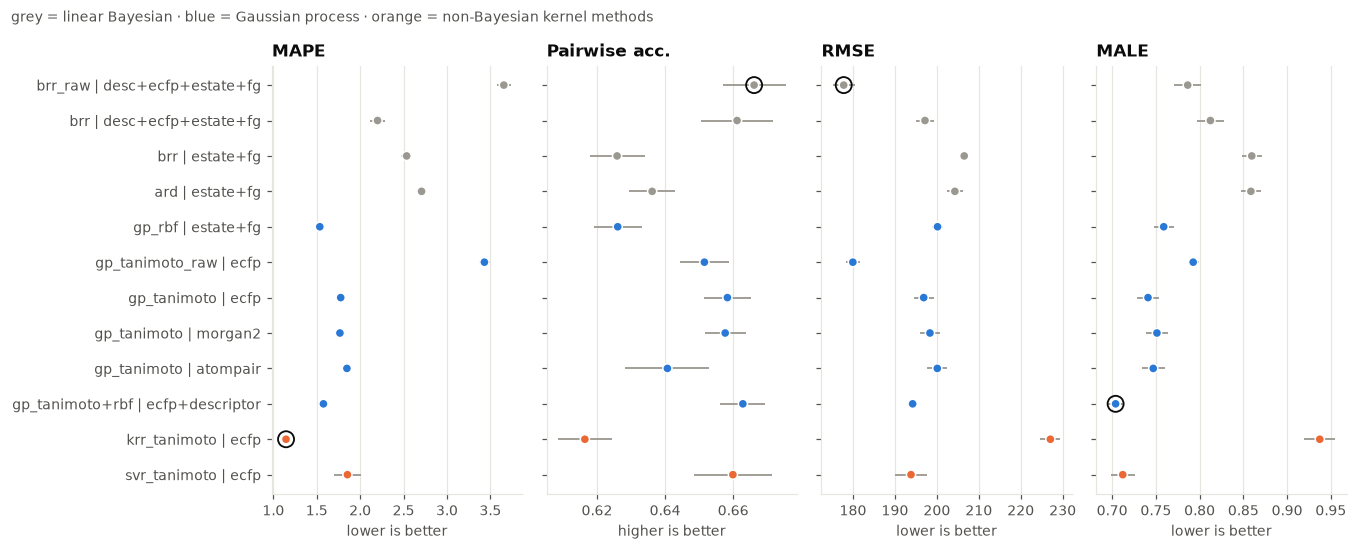

In [3]:
hl = {m: plots.GRAY if m.startswith(("brr", "ard")) else plots.ORANGE if m.startswith(("krr", "svr")) else plots.BLUE for m in summary["model"]}
fig = plots.metric_dots(summary, highlight=hl)
fig.suptitle("grey = linear Bayesian · blue = Gaussian process · orange = non-Bayesian kernel methods", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

Kernel ridge has the lowest MAPE but the worst pairwise accuracy. That is the MAPE trap from
notebook 00: its strong shrinkage pulls predictions toward low values, which MAPE rewards.

## Are the GP's uncertainties useful?

One advantage of a GP is a predictive standard deviation. For the Tanimoto + RBF GP (log space), we
check on all 5 × 10 test folds how often the truth falls inside the 68% and 95% intervals, and whether
larger predicted uncertainty goes with larger errors.

empirical coverage: {'68% interval': 0.772, '95% interval': 0.956}


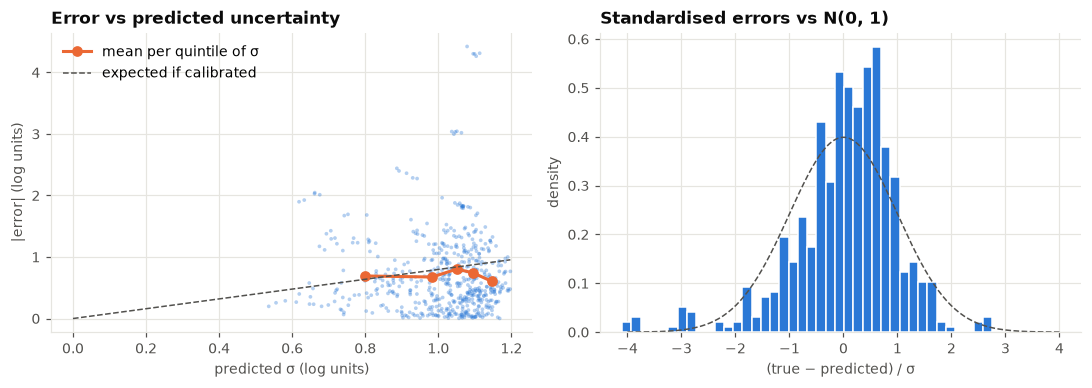

In [4]:
X_gp = ecfp_desc.to_numpy(dtype=float)
z = np.log(y)
mu_all, sd_all = np.zeros((len(repeats), len(y))), np.zeros((len(repeats), len(y)))
for r, folds in enumerate(repeats):
    for tr, te in folds:
        gp = TanimotoGP(n_fp=ecfp.shape[1]).fit(X_gp[tr], z[tr])
        mu_all[r, te], sd_all[r, te] = gp.predict(X_gp[te], return_std=True)
zscore = (z - mu_all) / sd_all
cover = {f"{p:.0%} interval": float(np.mean(np.abs(zscore) <= norm.ppf(0.5 + p / 2))) for p in (0.68, 0.95)}
print("empirical coverage:", {k: round(v, 3) for k, v in cover.items()})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
err = np.abs(z - mu_all).ravel()
sd = sd_all.ravel()
bins = pd.qcut(sd, 5)
binned = pd.DataFrame({"sd": sd, "err": err, "bin": bins}).groupby("bin", observed=True).mean()
axes[0].scatter(sd, err, s=6, color=plots.BLUE, alpha=0.35, edgecolors="none")
axes[0].plot(binned["sd"], binned["err"], color=plots.ORANGE, marker="o", linewidth=2, label="mean per quintile of σ")
axes[0].plot([0, sd.max()], [0, sd.max() * np.sqrt(2 / np.pi)], color=plots.INK_2, linestyle="--", linewidth=1, label="expected if calibrated")
axes[0].set(xlabel="predicted σ (log units)", ylabel="|error| (log units)")
axes[0].legend(loc="upper left")
axes[0].set_title("Error vs predicted uncertainty", loc="left")
axes[1].hist(zscore.ravel(), bins=40, density=True, color=plots.BLUE, edgecolor="white")
grid = np.linspace(-4, 4, 200)
axes[1].plot(grid, norm.pdf(grid), color=plots.INK_2, linestyle="--", linewidth=1)
axes[1].set(xlabel="(true − predicted) / σ", ylabel="density")
axes[1].set_title("Standardised errors vs N(0, 1)", loc="left")
fig.tight_layout()

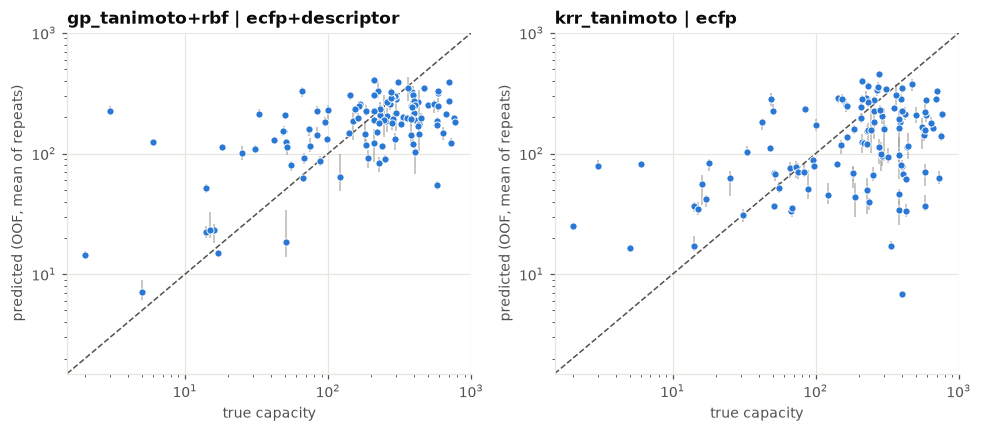

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["gp_tanimoto+rbf | ecfp+descriptor", "krr_tanimoto | ecfp"]):
    plots.pred_vs_true(y, load_oof(EXPERIMENT, name)[1], name, ax=ax)
fig.tight_layout()

## Takeaways

- **Best Bayesian model: GP with Tanimoto (ECFP) + RBF (descriptors)** on the log target: MAPE ≈ 1.58,
  PA ≈ 0.663, MALE ≈ 0.70. Better than BRR on MAPE and MALE, similar on pairwise accuracy.
- Tanimoto GPs with different fingerprints (ECFP, Morgan, atom pairs) are all close; adding the
  descriptor RBF kernel helps a little.
- Bayesian models don't beat random forest (notebook 01: PA 0.677, MAPE 1.40) on this data.
- The GP's uncertainty is **calibrated on average but not informative per substrate**: 95.6% of
  targets fall in the 95% interval (77% in the 68% one), but the error is flat across σ quintiles,
  so σ can't tell good predictions from bad ones. The few large errors (left tail of the histogram)
  are over-predictions of the tiny capacities, made with ordinary σ.
- The Tanimoto kernel on the raw target behaves like the other raw-target models (low RMSE, high MAPE);
  the log target is better here too.